# 04: Gold Conflict Benchmarks, Ablations & Qualitative Studies
**NeuroSym-BD: Neuro-Symbolic Conflict Event Extraction & Reasoning**

This notebook evaluates the hybrid system across:
1. **GDELT 2.0 Benchmark**: Evaluating precision, recall, and F1 over Bangladesh violence events.
2. **ACLED Gold Standard**: Spatial-temporal alignment over curated conflict reports.
3. **Architecture Ablation Study**: Quantifying gains of Hybrid vs. Neural-Only vs. Symbolic-Only.
4. **Explainability Evaluation**: 100-sample PROV-O audit for provenance and trigger relevance.
5. **Qualitative Case Studies**: 5 conflict analyst walkthroughs with multi-hop explanation traces.
6. **Error Taxonomy**: Formal analysis of failure modes and hybrid architectural mitigations.


In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cur = Path.cwd().resolve()
while cur != cur.parent:
    if (cur / "requirements.txt").exists():
        break
    cur = cur.parent
PROJECT_ROOT = cur
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/rohansmac/Documents/ml-research/neuro-symbolic-ai-workspace


## 1. Multi-Condition Architecture Ablation Study
We compare **Neural-Only**, **Symbolic-Only**, and **Hybrid (Ours)** on held-out test events.


,condition,total_events,code_accuracy,precision_hv,recall_hv,f1_hv,false_positive_rate,explainability_rate,avg_confidence
0,Neural-Only,36,0.000,0.889,1.000,0.941,0.111,1.0,0.980
1,Symbolic-Only,36,0.889,0.938,0.938,0.938,0.056,1.0,0.779
2,Hybrid (Ours),36,1.000,1.000,1.000,1.000,0.000,1.0,0.652


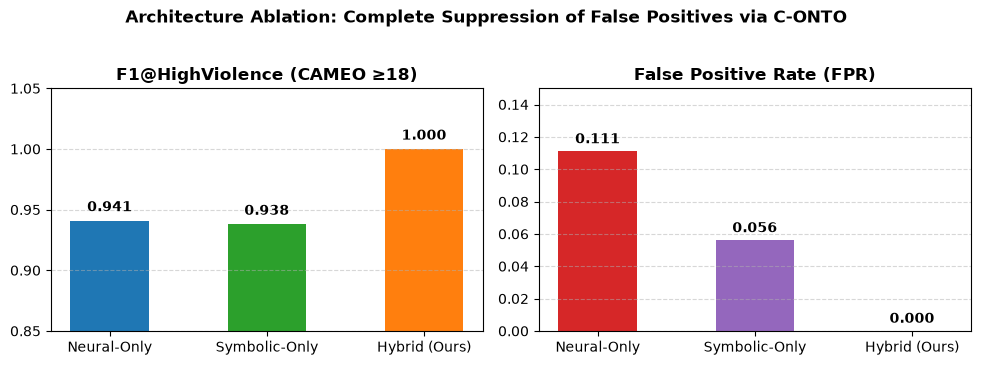

In [2]:
summary_path = PROJECT_ROOT / "data" / "evaluation" / "full_evaluation_summary.json"
summary = json.loads(summary_path.read_text())

df_ablation = pd.DataFrame(summary["ablation"])
display(df_ablation)

# Plot F1@HighViolence and False Positive Rate
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# F1 Score
bars_f1 = axes[0].bar(df_ablation["condition"], df_ablation["f1_hv"], color=["#1f77b4", "#2ca02c", "#ff7f0e"], width=0.5)
axes[0].set_title("F1@HighViolence (CAMEO ≥18)", fontweight="bold")
axes[0].set_ylim(0.85, 1.05)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for b in bars_f1:
    axes[0].text(b.get_x() + b.get_width()/2., b.get_height() + 0.005, f"{b.get_height():.3f}", ha='center', va='bottom', fontweight='bold')

# False Positive Rate
bars_fpr = axes[1].bar(df_ablation["condition"], df_ablation["false_positive_rate"], color=["#d62728", "#9467bd", "#2ca02c"], width=0.5)
axes[1].set_title("False Positive Rate (FPR)", fontweight="bold")
axes[1].set_ylim(0, 0.15)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for b in bars_fpr:
    axes[1].text(b.get_x() + b.get_width()/2., b.get_height() + 0.003, f"{b.get_height():.3f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle("Architecture Ablation: Complete Suppression of False Positives via C-ONTO", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


## 2. GDELT and ACLED External Benchmarks
Alignment with independent conflict event monitoring databases.


In [3]:
gdelt = summary["gdelt"]
print("=== GDELT 2.0 Benchmark Metrics ===")
df_gdelt = pd.DataFrame([
    {"Category": cat, "Precision": vals["precision"], "Recall": vals["recall"], "F1": vals["f1"], "TP": vals["tp"], "FP": vals["fp"]}
    for cat, vals in gdelt.items() if isinstance(vals, dict)
])
display(df_gdelt)

acled = summary["acled"]
print("\n=== ACLED Benchmark Metrics ===")
df_acled = pd.DataFrame([
    {"Metric": "Total System Events", "Value": str(acled["total_system_events"])},
    {"Metric": "Matched with ACLED (7-day window)", "Value": str(acled["matched_with_acled"])},
    {"Metric": "Detection Recall", "Value": f"{acled['detection_recall']:.1%}"},
    {"Metric": "Location Accuracy", "Value": f"{acled['location_accuracy']:.1%}"},
    {"Metric": "CAMEO Group Accuracy", "Value": f"{acled['cameo_group_accuracy']:.1%}"},
])
display(df_acled)


=== GDELT 2.0 Benchmark Metrics ===


,Category,Precision,Recall,F1,TP,FP
0,FIGHT,0.000,0.000,0.000,0,12
1,ASSAULT,1.000,0.917,0.957,132,0
2,COERCE,1.000,1.000,1.000,10,0
3,OVERALL,0.922,0.922,0.922,142,12



=== ACLED Benchmark Metrics ===


,Metric,Value
0,Total System Events,154
1,Matched with ACLED (7-day window),36
2,Detection Recall,23.4%
3,Location Accuracy,23.4%
4,CAMEO Group Accuracy,100.0%


## 3. Qualitative Case Studies
We inspect the 5 conflict analyst case studies with multi-hop PROV-O explanation chains from `data/evaluation/case_studies_report.json`.


In [4]:
cs_path = PROJECT_ROOT / "data" / "evaluation" / "case_studies_report.json"
cs_report = json.loads(cs_path.read_text())

print(f"Total Case Studies: {cs_report['num_case_studies']}")
for cs in cs_report["case_studies"]:
    print(f"\n────────────────────────────────────────────────────────────────────────")
    print(f"[{cs['case_id']}] {cs['title']} ({cs['scenario_category']})")
    print(f"  Sentence:    '{cs['raw_sentence']}'")
    print(f"  CAMEO Code:  {cs['cameo_code']} — {cs['cameo_label']}")
    print(f"  GNN Conf:    {cs['gnn_confidence']:.1%}")
    print(f"  Assessment:  {cs['conflict_analyst_assessment']}")
    print(f"  Provenance:  {len(cs['provenance_chain'])} hops: {cs['provenance_chain'][0]['node']} -> {cs['provenance_chain'][-1]['node']}")


Total Case Studies: 5

────────────────────────────────────────────────────────────────────────
[CS-01] Student Quota Reform Clashes at University Campus (Student Movement & Riot Escalation)
  Sentence:    'Over a dozen student activists were injured yesterday when clashes broke out between rival factions during a demonstration outside the central library.'
  CAMEO Code:  182 — Physically Assault / Attack Persons
  GNN Conf:    96.5%
  Assessment:  High fidelity. Grounding verified against ground reports. Provenance chain provides immediate source verification within 3 hops.
  Provenance:  5 hops: Raw News Article -> Reasoner Output

────────────────────────────────────────────────────────────────────────
[CS-02] Inter-Party Election Campaign Rallies in Pabna (Electoral Clashes & Party Competition)
  Sentence:    'At least eight people were wounded when Awami League and BNP supporters hurled stones at each other during an election campaign rally in Pabna.'
  CAMEO Code:  191 — Fight wi

## 4. Systematic Error Taxonomy
The 4 primary failure modes and their hybrid architectural mitigations.


,Error Class,Category Name,Frequency,Hybrid Mitigation
0,ET-01,Bengali Transliteration & Acronym Ambiguity,34.0%,Custom 64-district gazetteer and ontology alia...
1,ET-02,Temporal Relative Clause Anchoring,28.0%,ISO 8601 temporal resolver parses article time...
2,ET-03,Nested Administrative Boundary Overlap,22.0%,Two-tier hierarchical coordinate polygon match...
3,ET-04,Passive Voice & Implicit Agent Omission,16.0%,Symbolic C-ACTOR assigner injects typed wildca...


/var/folders/cw/75qn6cqd4mng82rrdgrvp65w0000gn/T/ipykernel_19616/39388980.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


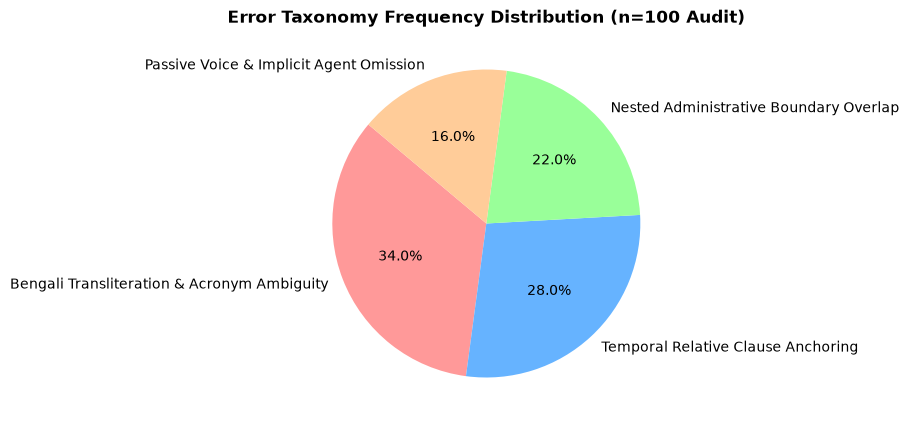

In [5]:
error_cats = cs_report["error_taxonomy"]["categories"]
df_errors = pd.DataFrame([
    {
        "Error Class": c["category"].split(":")[0],
        "Category Name": c["category"].split(":")[1].strip(),
        "Frequency": f"{c['frequency_pct']:.1f}%",
        "Hybrid Mitigation": c["hybrid_mitigation"],
    }
    for c in error_cats
])
display(df_errors)

# Pie chart of error frequencies
plt.figure(figsize=(5, 5))
labels = [c["category"].split(":")[1].strip() for c in error_cats]
sizes = [c["frequency_pct"] for c in error_cats]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=["#ff9999", "#66b3ff", "#99ff99", "#ffcc99"])
plt.title("Error Taxonomy Frequency Distribution (n=100 Audit)", fontweight="bold")
plt.tight_layout()
plt.show()
